# Tarea 1: Arreglo de Filtros de Bayer e Interpolación (Demosaicking)
### **Nombre:** Gonzalo Michea Valdés

## 1. Configuración

In [8]:
import argparse
from pathlib import Path
 
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
import urllib.request


### Descarga de imagene según el repositorio donde se encuentran las imagenes

script extraido directamente del repositorio: https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite/blob/master/image_scriping.py

In [9]:
print("start scripting.")

carpeta = Path("dataset")
carpeta.mkdir(exist_ok=True)

cnt = 0

for im in range(1, 25):

    nombre = f"{im:02d}.png"
    im_path = carpeta / nombre

    if im < 10:
        im_url = f"https://r0k.us/graphics/kodak/kodak/kodim0{im}.png"
    else:
        im_url = f"https://r0k.us/graphics/kodak/kodak/kodim{im}.png"

    try:
        urllib.request.urlretrieve(im_url, im_path)
        print(f"{nombre}: saved.")
        cnt += 1

    except Exception as error:
        print(f"{nombre}: isn't saved.")
        print("Error:", error)

print(f"saved image count: {cnt}")
print("finish scripting.")

start scripting.
01.png: saved.
02.png: saved.
03.png: saved.
04.png: saved.
05.png: saved.
06.png: saved.
07.png: saved.
08.png: saved.
09.png: saved.
10.png: saved.
11.png: saved.
12.png: saved.
13.png: saved.
14.png: saved.
15.png: saved.
16.png: saved.
17.png: saved.
18.png: saved.
19.png: saved.
20.png: saved.
21.png: saved.
22.png: saved.
23.png: saved.
24.png: saved.
saved image count: 24
finish scripting.


## 2. Definición de funciones 
### 2.1. Filtros de Bayer(RGGB)

In [10]:
def generar_mascara(H,W):

    B0 = np.array([[1, 0], [0 ,0]], dtype =np.float64) #R
    B1 = np.array([[0, 1],[1,0]], dtype =np.float64) #G
    B2 = np.array([[0, 0], [0, 1]], dtype =np.float64)

    reps = (H // 2 + 1, W // 2 + 1)
    R_mask = np.tile(B0, reps)[:H, :W]
    G_mask = np.tile(B1, reps)[:H, :W]
    B_mask = np.tile(B2, reps)[:H, :W]

    return R_mask, G_mask, B_mask

def crear_mosaico(img_rgb):
    H, W, _ = img_rgb.shape
    R_mask, G_mask, B_mask = generar_mascara(H, W)
    Y = (img_rgb[:,:,0]*R_mask + img_rgb[:,:,1]*G_mask + img_rgb[:,:,2]*B_mask)

    return Y, (R_mask,G_mask,B_mask)



### 2.2. Interpolación 2D (Demosaicking)

In [11]:
#Kernels clasicos de BAYER
KERNEL_G_BILINEAL = np.array([[0, 1, 0],
                                [1, 4, 1],
                                [0, 1, 0]], dtype=np.float64) / 4.0
 
KERNEL_RB_BILINEAL = np.array([[1, 2, 1],
                                [2, 4, 2],
                                [1, 2, 1]], dtype=np.float64) / 4.0

def _kernel_cubico_1d(radio_muestras, espaciado, a = 0.5):
    offsets = np.arange(-radio_muestras * espaciado, radio_muestras * espaciado + 1)
    x = np.abs(offsets) / espaciado
    w = np.zeros_like(x)
    m1 = x <= 1
    m2 = (x > 1) & (x < 2)
    w[m1] = (a + 2) * x[m1] ** 3 - (a + 3) * x[m1] ** 2 + 1
    w[m2] = a * x[m2] ** 3 - 5 * a * x[m2] ** 2 + 8 * a * x[m2] - 4 * a
    return w, offsets

def _kernel_cubico_2d(radio_muestras=2, espaciado=2, a=-0.5):
    w1d, _ = _kernel_cubico_1d(radio_muestras, espaciado, a)
    kernel = np.outer(w1d, w1d)
    return kernel

def demosaic_bilineal(Y, mascaras):
    # reconstruccion por convolucion con kernels bilineales estandar.
    R_mask, G_mask, B_mask = mascaras
    Ic_R = Y * R_mask
    Ic_G = Y * G_mask
    Ic_B = Y * B_mask
 
    R_hat = cv2.filter2D(Ic_R, -1, KERNEL_RB_BILINEAL, borderType=cv2.BORDER_REFLECT)
    G_hat = cv2.filter2D(Ic_G, -1, KERNEL_G_BILINEAL, borderType=cv2.BORDER_REFLECT)
    B_hat = cv2.filter2D(Ic_B, -1, KERNEL_RB_BILINEAL, borderType=cv2.BORDER_REFLECT)
 
    img = np.stack([R_hat, G_hat, B_hat], axis=-1)
    return np.clip(img, 0, 255)
 
 
def demosaic_bicubico(Y, mascaras, radio_muestras=2, espaciado=2, a=-0.5):
    # reconstruccion "bicubica" via convolucion normalizada.
    kernel = _kernel_cubico_2d(radio_muestras, espaciado, a)
    canales = []
    for mask in mascaras:
        muestras = Y * mask
        num = cv2.filter2D(muestras, -1, kernel, borderType=cv2.BORDER_REFLECT)
        den = cv2.filter2D(mask, -1, kernel, borderType=cv2.BORDER_REFLECT)
        den[den == 0] = 1e-8
        canales.append(num / den)
    img = np.stack(canales, axis=-1)
    return np.clip(img, 0, 255)

### 2.3. Metricas de calidad ( PSNR, SSIM, SAM)

In [12]:
def calcular_psnr(original, reconstruida):
    return psnr_fn(original, reconstruida, data_range=255)
 
 
def calcular_ssim(original, reconstruida):
    return ssim_fn(original, reconstruida, data_range=255, channel_axis=-1)
 

 
def calcular_sam(original, reconstruida, eps=1e-8):
    #Spectral Angle Mapper, promediado sobre todos los pixeles, en grados
    a = original.astype(np.float64)
    b = reconstruida.astype(np.float64)
    num = np.sum(a * b, axis=2)
    den = np.sqrt(np.sum(a ** 2, axis=2)) * np.sqrt(np.sum(b ** 2, axis=2)) + eps
    cos_theta = np.clip(num / den, -1, 1)
    theta = np.arccos(cos_theta)
    return np.degrees(np.mean(theta))

def guardar_figura_comparativa(img_rgb, Y, mascaras, ruta_salida, recorte=120):
    # genera una figura con original, mosaico Bayer, bilineal y bicúbico
    
    H, W, _ = img_rgb.shape
    
    # Evita que el recorte exceda los límites de imágenes pequeñas
    recorte = min(recorte, H // 2 - 1, W // 2 - 1)
    cy, cx = H // 2, W // 2
    
    sl = (
        slice(cy - recorte, cy + recorte),
        slice(cx - recorte, cx + recorte)
    )

    recon_bilineal = demosaic_bilineal(Y, mascaras)
    recon_bicubico = demosaic_bicubico(Y, mascaras)

    fig, axs = plt.subplots(1, 4, figsize=(16, 4))

    axs[0].imshow(np.clip(img_rgb[sl], 0, 255).astype(np.uint8))
    axs[0].set_title("Original")

    axs[1].imshow(Y[sl], cmap="gray")
    axs[1].set_title("Mosaico Bayer (Y)")

    axs[2].imshow(np.clip(recon_bilineal[sl], 0, 255).astype(np.uint8))
    axs[2].set_title("Demosaick bilineal\n(zipper / falso color)")

    axs[3].imshow(np.clip(recon_bicubico[sl], 0, 255).astype(np.uint8))
    axs[3].set_title("Demosaick bicúbico\n(conv. normalizada)")

    for ax in axs:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    plt.close(fig)



## 3. Procesamiento de las Imagenes de KODAK

In [13]:
carpeta_dataset = Path("dataset")
carpeta_salida = Path("resultados")

metodos = ("bilineal", "bicubico")

carpeta_salida.mkdir(exist_ok=True, parents=True)

rutas = sorted(carpeta_dataset.glob("*.png"))

filas = []

for ruta in rutas:
    # OpenCV carga por defecto en BGR
    img_bgr = cv2.imread(str(ruta), cv2.IMREAD_COLOR)

    # Convertir a RGB y usar float para los cálculos
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float64)

    # Crear el mosaico Bayer
    Y, mascaras = crear_mosaico(img_rgb)

    # Reconstruir y evaluar cada método
    for metodo in metodos:
        if metodo == "bilineal":
            recon = demosaic_bilineal(Y, mascaras)

        elif metodo == "bicubico":
            recon = demosaic_bicubico(Y, mascaras)

        # Calcular métricas
        psnr_v = calcular_psnr(img_rgb, recon)
        ssim_v = calcular_ssim(img_rgb, recon)
        sam_v = calcular_sam(img_rgb, recon)

        filas.append({
            "imagen": ruta.name,
            "metodo": metodo,
            "PSNR_dB": psnr_v,
            "SSIM": ssim_v,
            "SAM_deg": sam_v
        })
    ruta_figura = carpeta_salida / f"comparativo_{ruta.stem}.png"

    guardar_figura_comparativa(
        img_rgb=img_rgb,
        Y=Y,
        mascaras=mascaras,
        ruta_salida=ruta_figura
    )
    print(f"Procesada: {ruta.name}")


df = pd.DataFrame(filas)

# Métricas por imagen y por método
ruta_metricas = carpeta_salida / "metricas_por_imagen.csv"
df.to_csv(ruta_metricas, index=False)

# Media y desviación estándar por método
resumen = (
    df.groupby("metodo")[["PSNR_dB", "SSIM", "SAM_deg"]]
      .agg(["mean", "std"])
)

ruta_resumen = carpeta_salida / "metricas_resumen.csv"
resumen.to_csv(ruta_resumen)

print("\n=== Resumen: media ± desviación estándar ===")
display(resumen)

Procesada: 01.png
Procesada: 02.png
Procesada: 03.png
Procesada: 04.png
Procesada: 05.png
Procesada: 06.png
Procesada: 07.png
Procesada: 08.png
Procesada: 09.png
Procesada: 10.png
Procesada: 11.png
Procesada: 12.png
Procesada: 13.png
Procesada: 14.png
Procesada: 15.png
Procesada: 16.png
Procesada: 17.png
Procesada: 18.png
Procesada: 19.png
Procesada: 20.png
Procesada: 21.png
Procesada: 22.png
Procesada: 23.png
Procesada: 24.png

=== Resumen: media ± desviación estándar ===


PSNR_dB                SSIM             SAM_deg          
               mean       std      mean       std      mean       std
metodo                                                               
bicubico  29.187995  2.952686  0.880872  0.046282  2.312312  0.987835
bilineal  29.214317  2.754055  0.891313  0.040252  2.508675  1.030501

## 4. BONUS: Filtro lineal de Malvar-He-Cutler (2004)
Procesamiento del paper de MALVAR

In [19]:
#Kernels del filtro lineal de Malvar-He-Cutler, normalizados por 1/8.
#Son simetricos bajo rotacion de 180 grados, por lo que correlacion 2D
#(cv2.filter2D) equivale a convolucion 2D.

_MHC_G_AT_RB = np.array([
    [0, 0, -1, 0, 0],
    [0, 0,  2, 0, 0],
    [-1, 2, 4, 2, -1],
    [0, 0,  2, 0, 0],
    [0, 0, -1, 0, 0],
], dtype=np.float64) / 8.0

# R en verde, fila de R / columna de B (y por simetria: B en verde, fila de B / columna de R)
_MHC_A = np.array([
    [0, 0, 0.5, 0, 0],
    [0, -1, 0, -1, 0],
    [-1, 4, 5, 4, -1],
    [0, -1, 0, -1, 0],
    [0, 0, 0.5, 0, 0],
], dtype=np.float64) / 8.0

# R en verde, fila de B / columna de R (y por simetria: B en verde, fila de R / columna de B)
_MHC_B = np.array([
    [0, 0, -1, 0, 0],
    [0, -1, 4, -1, 0],
    [0.5, 0, 5, 0, 0.5],
    [0, -1, 4, -1, 0],
    [0, 0, -1, 0, 0],
], dtype=np.float64) / 8.0

# R en azul (y por simetria: B en rojo) -> posicion diagonalmente opuesta
_MHC_DIAG = np.array([
    [0, 0, -1.5, 0, 0],
    [0, 2, 0, 2, 0],
    [-1.5, 0, 6, 0, -1.5],
    [0, 2, 0, 2, 0],
    [0, 0, -1.5, 0, 0],
], dtype=np.float64) / 8.0


def _mascaras_subtipo_verde(H, W):
    # separa la mascara G en los 2 subtipos que usa el paper:
    # G1: fila compartida con R, columna compartida con B (fila par, col impar)
    # G2: fila compartida con B, columna compartida con R (fila impar, col par)
    filas = np.arange(H).reshape(-1, 1)
    cols = np.arange(W).reshape(1, -1)
    G1 = ((filas % 2 == 0) & (cols % 2 == 1)).astype(np.float64)
    G2 = ((filas % 2 == 1) & (cols % 2 == 0)).astype(np.float64)
    return G1, G2


def demosaic_malvar(Y, mascaras):
    # Demosaicking con el filtro lineal de Malvar, He y Cutler (2004).
    R_mask, G_mask, B_mask = mascaras
    H, W = Y.shape
    G1, G2 = _mascaras_subtipo_verde(H, W)

    conv_G = cv2.filter2D(Y, -1, _MHC_G_AT_RB, borderType=cv2.BORDER_REFLECT)
    conv_A = cv2.filter2D(Y, -1, _MHC_A, borderType=cv2.BORDER_REFLECT)
    conv_B = cv2.filter2D(Y, -1, _MHC_B, borderType=cv2.BORDER_REFLECT)
    conv_D = cv2.filter2D(Y, -1, _MHC_DIAG, borderType=cv2.BORDER_REFLECT)

    # Canal G: conocido en G_mask, se interpola en R y B con conv_G
    G_hat = G_mask * Y + (R_mask + B_mask) * conv_G

    # Canal R: conocido en R_mask; en G1 usa kernel A, en G2 usa kernel B;
    # en B_mask usa el kernel diagonal
    R_hat = R_mask * Y + G1 * conv_A + G2 * conv_B + B_mask * conv_D

    # Canal B: conocido en B_mask; en G1 usa kernel B, en G2 usa kernel A
    # (roles invertidos respecto a R por simetria); en R_mask usa diagonal
    B_hat = B_mask * Y + G1 * conv_B + G2 * conv_A + R_mask * conv_D

    img = np.stack([R_hat, G_hat, B_hat], axis=-1)
    return np.clip(img, 0, 255)


### 4.2 Metricas de calidad ( PSNR, SSIM, SAM)

In [20]:
def guardar_figura_comparativa(img_rgb, Y, mascaras, ruta_salida, recorte=120):
    # genera una figura con original, mosaico Bayer, bilineal, bicubico y malvar(bonus)
    
    H, W, _ = img_rgb.shape
    
    # Evita que el recorte exceda los límites de imágenes pequeñas
    recorte = min(recorte, H // 2 - 1, W // 2 - 1)
    cy, cx = H // 2, W // 2
    
    sl = (
        slice(cy - recorte, cy + recorte),
        slice(cx - recorte, cx + recorte)
    )

    recon_bilineal = demosaic_bilineal(Y, mascaras)
    recon_bicubico = demosaic_bicubico(Y, mascaras)
    recon_malvar = demosaic_malvar(Y, mascaras)

    fig, axs = plt.subplots(1, 5, figsize=(20, 4))

    axs[0].imshow(np.clip(img_rgb[sl], 0, 255).astype(np.uint8))
    axs[0].set_title("Original")

    axs[1].imshow(Y[sl], cmap="gray")
    axs[1].set_title("Mosaico Bayer (Y)")

    axs[2].imshow(np.clip(recon_bilineal[sl], 0, 255).astype(np.uint8))
    axs[2].set_title("Bilineal\n(zipper / falso color)")

    axs[3].imshow(np.clip(recon_bicubico[sl], 0, 255).astype(np.uint8))
    axs[3].set_title("Bicubico\n(conv. normalizada)")

    axs[4].imshow(np.clip(recon_malvar[sl], 0, 255).astype(np.uint8))
    axs[4].set_title("Malvar-He-Cutler 2004\n(BONUS)")

    for ax in axs:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    plt.close(fig)


### 4.3 Procesamiento de las Imagenes de KODAK

In [21]:
carpeta_dataset = Path("dataset")
carpeta_salida = Path("resultados_bonus")

metodos = ("bilineal", "bicubico", "malvar")

carpeta_salida.mkdir(exist_ok=True, parents=True)

rutas = sorted(carpeta_dataset.glob("*.png"))

filas = []

for ruta in rutas:
    # OpenCV carga por defecto en BGR
    img_bgr = cv2.imread(str(ruta), cv2.IMREAD_COLOR)

    # Convertir a RGB y usar float para los cálculos
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float64)

    # Crear el mosaico Bayer
    Y, mascaras = crear_mosaico(img_rgb)

    # Reconstruir y evaluar cada método
    for metodo in metodos:
        if metodo == "bilineal":
            recon = demosaic_bilineal(Y, mascaras)

        elif metodo == "bicubico":
            recon = demosaic_bicubico(Y, mascaras)

        elif metodo == "malvar":
            recon = demosaic_malvar(Y, mascaras)

        # Calcular métricas
        psnr_v = calcular_psnr(img_rgb, recon)
        ssim_v = calcular_ssim(img_rgb, recon)
        sam_v = calcular_sam(img_rgb, recon)

        filas.append({
            "imagen": ruta.name,
            "metodo": metodo,
            "PSNR_dB": psnr_v,
            "SSIM": ssim_v,
            "SAM_deg": sam_v
        })
    ruta_figura = carpeta_salida / f"comparativobonus_{ruta.stem}.png"

    guardar_figura_comparativa(
        img_rgb=img_rgb,
        Y=Y,
        mascaras=mascaras,
        ruta_salida=ruta_figura
    )
    print(f"Procesada: {ruta.name}")


df = pd.DataFrame(filas)

# Métricas por imagen y por método
ruta_metricas = carpeta_salida / "metricas_por_imagen.csv"
df.to_csv(ruta_metricas, index=False)

# Media y desviación estándar por método
resumen = (
    df.groupby("metodo")[["PSNR_dB", "SSIM", "SAM_deg"]]
      .agg(["mean", "std"])
)

ruta_resumen = carpeta_salida / "metricas_resumen.csv"
resumen.to_csv(ruta_resumen)

print("\n=== Resumen: media ± desviación estándar ===")
display(resumen)


Procesada: 01.png
Procesada: 02.png
Procesada: 03.png
Procesada: 04.png
Procesada: 05.png
Procesada: 06.png
Procesada: 07.png
Procesada: 08.png
Procesada: 09.png
Procesada: 10.png
Procesada: 11.png
Procesada: 12.png
Procesada: 13.png
Procesada: 14.png
Procesada: 15.png
Procesada: 16.png
Procesada: 17.png
Procesada: 18.png
Procesada: 19.png
Procesada: 20.png
Procesada: 21.png
Procesada: 22.png
Procesada: 23.png
Procesada: 24.png

=== Resumen: media ± desviación estándar ===


PSNR_dB                SSIM             SAM_deg          
               mean       std      mean       std      mean       std
metodo                                                               
bicubico  29.187995  2.952686  0.880872  0.046282  2.312312  0.987835
bilineal  29.214317  2.754055  0.891313  0.040252  2.508675  1.030501
malvar    35.356441  2.946406  0.968796  0.008153  1.696664  0.689716

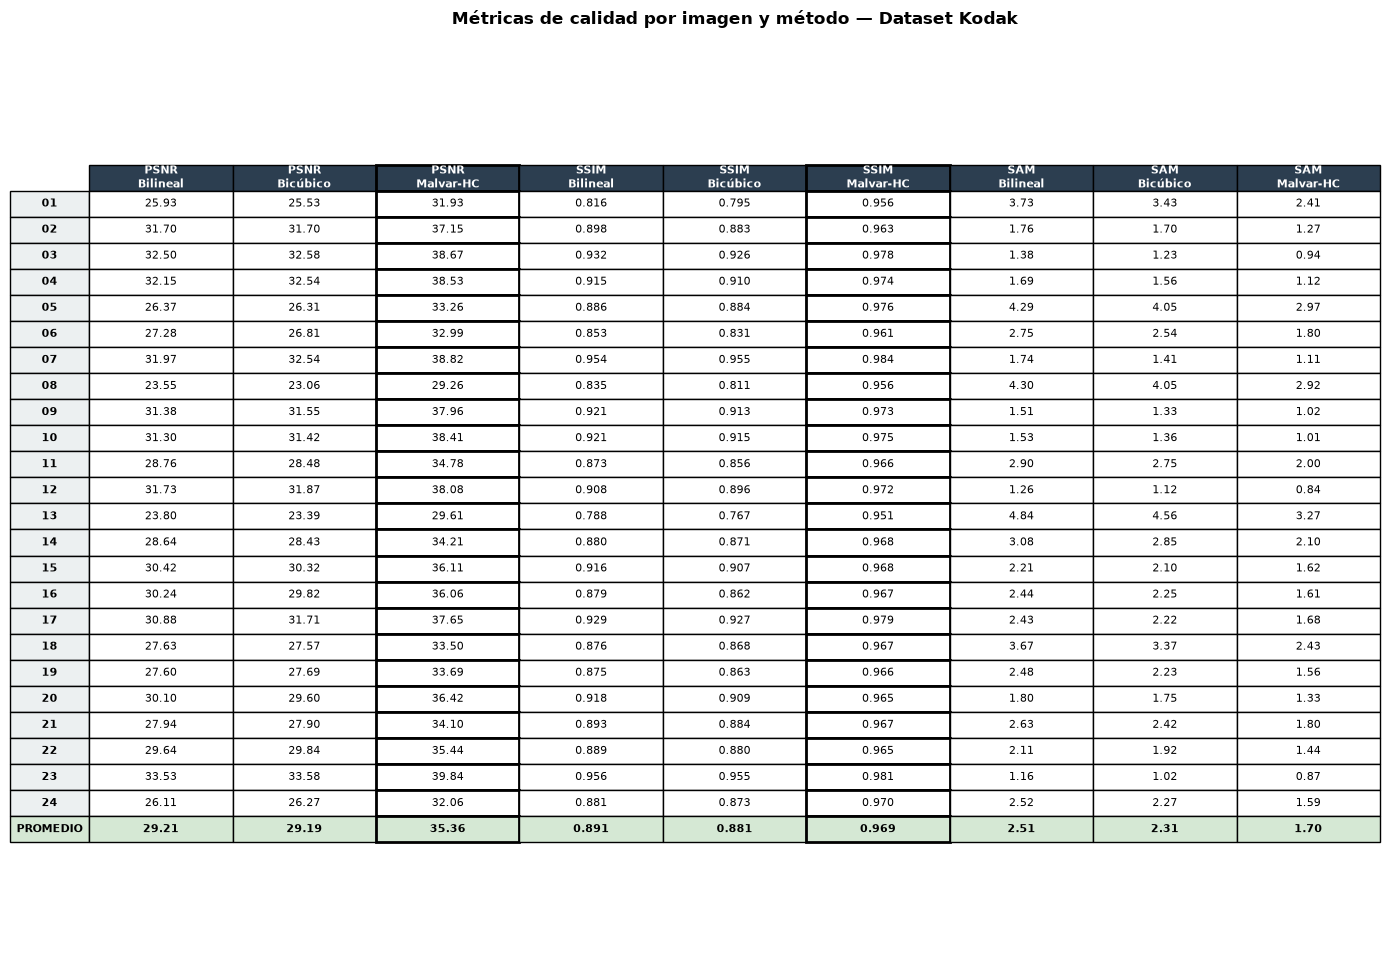

In [ ]:
# ==== Tabla completa de metricas (imagen) ====
metodos_orden = ["bilineal", "bicubico", "malvar"]
nombres_metodos = {"bilineal": "Bilineal", "bicubico": "Bicúbico", "malvar": "Malvar-HC"}

piv_psnr = df.pivot(index="imagen", columns="metodo", values="PSNR_dB")[metodos_orden]
piv_ssim = df.pivot(index="imagen", columns="metodo", values="SSIM")[metodos_orden]
piv_sam  = df.pivot(index="imagen", columns="metodo", values="SAM_deg")[metodos_orden]

imagenes = sorted(df["imagen"].unique())

col_labels = []
for metrica in ["PSNR", "SSIM", "SAM"]:
    for m in metodos_orden:
        col_labels.append(f"{metrica}\n{nombres_metodos[m]}")

cell_text = []
for im in imagenes:
    fila = [f"{piv_psnr.loc[im, m]:.2f}" for m in metodos_orden]
    fila += [f"{piv_ssim.loc[im, m]:.3f}" for m in metodos_orden]
    fila += [f"{piv_sam.loc[im, m]:.2f}" for m in metodos_orden]
    cell_text.append(fila)

row_labels = [im.replace(".png", "") for im in imagenes]

# Fila de promedio al final (reutiliza el "resumen" ya calculado mas arriba)
prom = resumen.copy()
prom.columns = ["_".join(c) for c in prom.columns]  # aplanar columnas multiindex
fila_prom = [f"{resumen.loc[m, ('PSNR_dB','mean')]:.2f}" for m in metodos_orden]
fila_prom += [f"{resumen.loc[m, ('SSIM','mean')]:.3f}" for m in metodos_orden]
fila_prom += [f"{resumen.loc[m, ('SAM_deg','mean')]:.2f}" for m in metodos_orden]
cell_text.append(fila_prom)
row_labels.append("PROMEDIO")

fig, ax = plt.subplots(figsize=(14, 0.35 * len(row_labels) + 1))
ax.axis("off")

tabla = ax.table(
    cellText=cell_text,
    rowLabels=row_labels,
    colLabels=col_labels,
    cellLoc="center",
    rowLoc="center",
    loc="center",
)
tabla.auto_set_font_size(False)
tabla.set_fontsize(8)
tabla.scale(1, 1.3)

n_rows = len(row_labels)
for (row, col), cell in tabla.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#2c3e50")
    if col == -1:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#ecf0f1")
    if col in (2, 5) and col != -1:
        cell.set_linewidth(2.0)
    if row == n_rows:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#d5e8d4")

plt.title("Métricas de calidad por imagen y método",
          fontsize=12, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig(carpeta_salida / "tabla_metricas_completa.png", dpi=180, bbox_inches="tight")
plt.show()